In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.optimize import fsolve
from scipy.optimize import root_scalar
from scipy.optimize import approx_fprime
from scipy.optimize import root
from scipy.signal import argrelextrema
import numdifftools as nd
from matplotlib import colormaps
import warnings
plt.rcParams["figure.dpi"] = 120

# Previous useful code

#### Defining parameters and functions

In [2]:
m_s = 100
m_B = 939
B_one_forth = 170  # 280 for muB/2 in QM
B = B_one_forth**4
Delta_P = 7e+7
muK = np.linspace(-90,90,50)
muB = np.linspace(980, 1050,50)
muK_grid, muB_grid = np.meshgrid(muK, muB)

def P_f(mu, m):
    k_F = np.sqrt(mu**2 - m**2)
    return ((2*k_F**3 - 3*m**2*k_F)*mu + 3*m**4*np.log((k_F+mu)/m)) / (24*np.pi**2)

def PQM(muB, muK, B):
    return ((muB/3 + muK/2)**4 + (muB/3)**4) * 3/(12*np.pi**2) + 3*P_f(muB/3 - muK/2, m_s) - B
    
def PNM(muB):
    muE = (muB**2 - m_B**2) / (2 * muB) # solved using MMA, this corresponds to the real solution
    muQ = -muE
    mun = muB
    mup = muB + muQ
    return P_f(mun, m_B) + P_f(mup, m_B) + muE**4 / (12 * np.pi**2)

PQM_wrap = lambda Mu: PQM(Mu[0], Mu[1], B)

def extract_contour_coords(X, Y, Z, level):
    fig, ax = plt.subplots()
    contour_obj = ax.contour(X, Y, Z, levels=[level])
    # Directly access the paths from the contour object
    paths = []
    for c in contour_obj.get_paths():
        paths.append(c.vertices)
    plt.close(fig)  # Close the plot if you only want data
    if not paths:
        raise RuntimeError(f"No contours found at level {level}")
    return paths[0][:, 0], paths[0][:, 1]

#### Calculating typical values

In [3]:
P_difference = lambda x: PQM(x, 0, B) - PNM(x)
muB_crit = fsolve(P_difference, 1050)[0]
P_crit = PNM(muB_crit)

PNM_minus_PShift = lambda x: PNM(x) - P_crit - Delta_P
PQM_minus_PShift = lambda x: PQM(x,0,B) - P_crit - Delta_P
muB_N = fsolve(PNM_minus_PShift, 1050)[0]
muB_Q = fsolve(PQM_minus_PShift, 1050)[0]

In [4]:
P_crit, muB_crit, muB_N, muB_Q

(np.float64(36195710.24264651),
 np.float64(1002.1259123577354),
 np.float64(1035.2787442854603),
 np.float64(1020.9562652484549))

#### Doing some plotting-1

Text(1002.4285714285714, 79.74047044476738, '$Q^*_,\\ \\mu_B = 1001.43\\ \\mathrm{MeV},\\ \\mu_K = 79.74\\ \\mathrm{MeV}$')

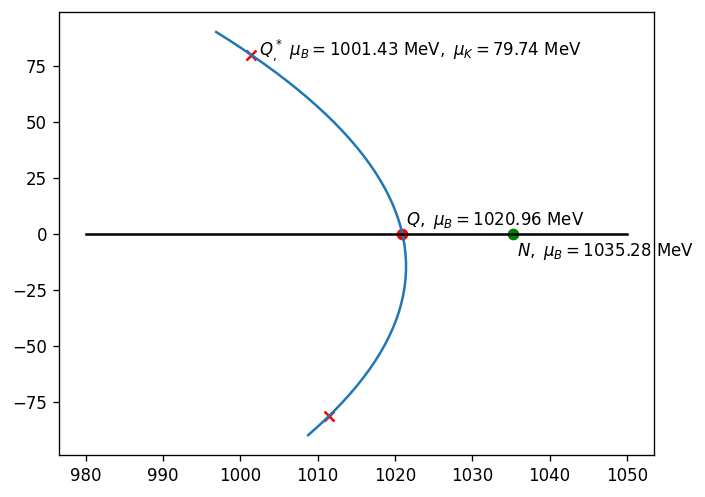

In [5]:
P_QM = PQM(muB_grid, muK_grid, B) #((muB_grid/3 + muK_grid/2)**4 + (muB_grid/3)**4) * 3/(12*np.pi**2) + 3*P_f(muB_grid/3 - muK_grid/2, m_s) - B
P_NM = PNM(muB_grid)

muB_contour_coor, muK_contour_coor = extract_contour_coords(muB_grid, muK_grid, P_QM, level = P_crit + Delta_P)

mu_average = []
epsilon = np.sqrt(np.finfo(float).eps)
for i in range(len(muB_contour_coor)):
    muB_Qstar = muB_contour_coor[i]
    muK_Qstar = muK_contour_coor[i]
    Qstar = np.array([muB_Qstar, muK_Qstar])
    grad = approx_fprime(Qstar, PQM_wrap, epsilon) # calculate n=∂P/∂mu
    nB_Qstar = grad[0]
    nK_Qstar = grad[1]
    mu_average.append( muB_Qstar + nK_Qstar * muK_Qstar / nB_Qstar)
difference = np.abs(np.array(mu_average) - muB_N)
minima_ind = argrelextrema(difference, np.less)[0]


plt.plot(muB_contour_coor, muK_contour_coor)
plt.plot(muB, np.zeros(len(muB)), 'k')

plt.scatter(muB_Q, 0, c='r')
plt.text(muB_Q+0.5, 4, rf"$Q,\ \mu_B = {muB_Q.item():.2f}\ \mathrm{{MeV}}$")

plt.scatter(muB_N, 0, c='g')
plt.text(muB_N+0.5, -10, rf"$N,\ \mu_B = {muB_N.item():.2f}\ \mathrm{{MeV}}$")

plt.scatter(muB_contour_coor[minima_ind[0]],muK_contour_coor[minima_ind[0]], marker='x', c='r')
plt.scatter(muB_contour_coor[minima_ind[1]],muK_contour_coor[minima_ind[1]], marker='x', c='r')
plt.text(muB_contour_coor[minima_ind[1]]+1, muK_contour_coor[minima_ind[1]], rf"$Q^*_,\ \mu_B = {muB_contour_coor[minima_ind[1]]:.2f}\ \mathrm{{MeV}},\ \mu_K = {muK_contour_coor[minima_ind[1]]:.2f}\ \mathrm{{MeV}}$")

#### Doing some plotting-2

In [6]:
# this code calculates aQstar 

def aQstar_and_other_stuff(muB, muK, P_crit, Delta_P):  # the muB should be understood as muB_Qstar, and same for muK
    # calculate nB_Qstar, nK_Qstar using partial derivitives
    Qstar = np.array([muB, muK])
    grad_Qstar = approx_fprime(Qstar, PQM_wrap, epsilon) # calculate n=∂P/∂mu at Qstar!!!
    nB_Qstar = grad_Qstar[0]
    nK_Qstar = grad_Qstar[1]

    # solve for muB_Q
    PQM_at_Q = lambda x: PQM(x, 0, B = (170)**4) - P_crit - Delta_P
    muB_Q = fsolve(PQM_at_Q, 1050)[0]  # 1050 is the starting point of numerical root finding

    # calculate nB_Q and nK_Q using partial derivitives
    Q = np.array([muB_Q, 0])  # the point Q
    grad_Q = approx_fprime(Q, PQM_wrap, epsilon)
    nB_Q = grad_Q[0]
    nK_Q = grad_Q[1]

    return (nK_Qstar - nK_Q)/nB_Q , nB_Q, muB_Q

aQstar_and_other_stuff(996.85, 90.00, P_crit, Delta_P)

(np.float64(0.38644454205099243),
 np.float64(3824880.0),
 np.float64(1020.9562652484549))

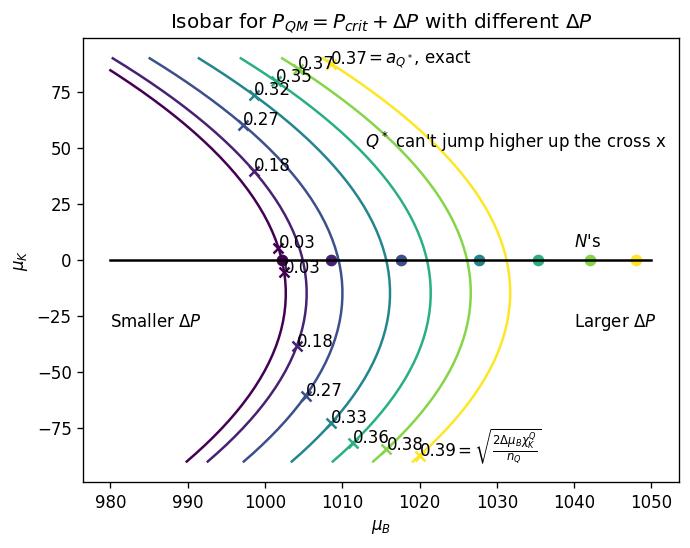

In [7]:
cmap = colormaps['viridis']

Delta = np.array([2e+5, 1e+7, 2.7e+7, 5e+7, 7e+7, 9e+7, 1.1e+8]) #P_crit * np.array([0.1, 0.2, 0.3, 0.4, 0.5])

for Delta_P in Delta:
    muB_contour_coor, muK_contour_coor = extract_contour_coords(muB_grid, muK_grid, P_QM, level = P_crit + Delta_P)
    mu_average = []
    for i in range(len(muB_contour_coor)):
        muB_Qstar = muB_contour_coor[i]
        muK_Qstar = muK_contour_coor[i]
        Qstar = np.array([muB_Qstar, muK_Qstar])
        grad = approx_fprime(Qstar, PQM_wrap, epsilon) # calculate n=∂P/∂mu at Qstar!!!
        nB_Qstar = grad[0]
        nK_Qstar = grad[1]
        mu_average.append( muB_Qstar + nK_Qstar * muK_Qstar / nB_Qstar)
    PNM_minus_PShift = lambda muB: PNM(muB) - P_crit - Delta_P
    muB_N = fsolve(PNM_minus_PShift, 1050)  # 1050 is the starting point of numerical root finding
    difference = np.abs(np.array(mu_average) - muB_N)
    minima_ind = argrelextrema(difference, np.less)[0]  # this is where the cross is (the index) along the contour line

    muB_Qstar_down = muB_contour_coor[minima_ind[0]]
    muK_Qstar_down = muK_contour_coor[minima_ind[0]]
    muB_Qstar_up = muB_contour_coor[minima_ind[1]]
    muK_Qstar_up = muK_contour_coor[minima_ind[1]]
    
    a_Q_star, nBQ, muBQ = aQstar_and_other_stuff(muB_Qstar_up, muK_Qstar_up, P_crit, Delta_P) # should only use upper value

    # the following calculates a_Q_star_max using the analytical approximation from taylor expansion
    PQM_at_Q = lambda x: PQM(muBQ, x, B = (170)**4) - P_crit - Delta_P
    d2f = nd.Derivative(PQM_at_Q, n=2)
    chiK_Q = d2f(0)
    a_Q_star_max = np.sqrt((2 * (muB_N - muBQ) * chiK_Q) / nBQ)[0]

    # plotting the crosses and the corresponding exact aQstar (on upper branch) and analytical aQstar (on down branch)
    col = cmap(Delta_P/Delta[-1])
    plt.plot(muB_contour_coor, muK_contour_coor, color = col)
    plt.scatter(muB_Qstar_down,muK_Qstar_down, marker='x', color=col)
    plt.scatter(muB_Qstar_up,muK_Qstar_up, marker='x', color=col)
    plt.text(muB_Qstar_up,muK_Qstar_up, f"{a_Q_star:.2f}")
    plt.text(muB_Qstar_down,muK_Qstar_down, f"{a_Q_star_max:.2f}")
    plt.scatter(muB_N, 0, color=col)
    

# Putting down texts
plt.text(1040, -30, r"Larger $\Delta P$")
plt.text(980, -30, r"Smaller $\Delta P$")
plt.text(1013, 50, r"$Q^*$ can't jump higher up the cross x")
plt.text(1013, 88, r"$=a_{Q^*}$, exact")
plt.text(1024.5, -87.5, r"$=\sqrt{\frac{2\Delta\mu_B\chi_K^Q}{n_Q}}$")
plt.text(1040, 6, r"$N$'s")
plt.plot(muB, np.zeros(len(muB)), 'k')
plt.xlabel(r"$\mu_B$")
plt.ylabel(r"$\mu_K$")
plt.title(r"Isobar for $P_{QM} = P_{crit} + \Delta P$ with different $\Delta P$") 
plt.show()

# Prior to May 22, Using Walecka model for NM

$$
P = \frac{1}{2} {m_\omega^2} \overline{\omega}_0^2 
- \frac{1}{2} {m_\sigma^2} \overline{\sigma}^2 + \frac{1}{4\pi^2} \left[ 
\left( \frac{2}{3} k_F^3 - (m_N^*)^2 k_F \right) E_F^* 
+ (m_N^*)^4 \ln \left( \frac{k_F + E_F^*}{m_N^*} \right) 
\right]\;,\quad E_F^* = \sqrt{k^2_F + (m_N^*)^2}
$$

#### parameters

In [9]:
# coupling constants are determined by requiring that the model reproduces saturation density and binding energy per nucleon
alpha_sigma = 9.573
g_sigma = np.sqrt(alpha_sigma * 4 * np.pi)

alpha_omega = 14.717
g_omega = np.sqrt(alpha_omega * 4 * np.pi)

m_sigma = 550  # MeV
m_omega = 783  # MeV
m_N = m_B

In [11]:
mu_B = 980
g_sigma, g_omega

(np.float64(10.968038379366675), np.float64(13.5992380790809))

the actual baryon chemical potential in Walecka model is the following
$$
\mu_B = \sqrt{k_F^2 + (m_N - g_\sigma \overline{\sigma})^2} + g_\omega \overline{\omega}_0\;,\quad\mbox{in comparasion with }\quad \mu_B = \sqrt{k_F^2 + m_N^2}
$$

gonna solve for the system of equations, with given $\mu_B$ to get the mean field values and Fermi momentum:
$$
\left\{
\begin{aligned}
& \sqrt{k_F^2 + (m_N - g_\sigma \overline{\sigma})^2} + g_\omega \overline{\omega}_0 = \mu_B \\
& \overline{\omega}_0 - \frac{g_\omega}{m_\omega^2}\frac{2k_F^3}{3\pi^2} = 0 \\
& -\overline{\sigma} + \frac{g_\sigma}{m_\sigma^2}\frac{m_N - g_\sigma \overline{\sigma}}{\pi^2}\left[ k_F\sqrt{k_F^2 + (m_N - g_\sigma \overline{\sigma})^2} - (m_N - g_\sigma \overline{\sigma})^2\ln\frac{k_F + \sqrt{k_F^2 + (m_N - g_\sigma \overline{\sigma})^2}}{m_N - g_\sigma \overline{\sigma}} \right] = 0
\end{aligned}
\right.
$$

In [11]:
# --- System of equations ---
def system(vars):
    k_F, sigma_bar, omega_0_bar = vars
    if k_F <= 0 or sigma_bar < 0:
        return [1e6, 1e6, 1e6]

    m_star = m_N - g_sigma * sigma_bar
    if m_star <= 0:
        return [1e6, 1e6, 1e6]

    E_F = np.sqrt(k_F**2 + m_star**2)
    eq1 = E_F + g_omega * omega_0_bar - mu_B

    eq2 = omega_0_bar - (g_omega / m_omega**2) * (2 * k_F**3) / (3 * np.pi**2)

    log_arg = (k_F + E_F) / m_star
    if log_arg <= 0:
        return [1e6, 1e6, 1e6]
    scalar_term = k_F * E_F - m_star**2 * np.log(log_arg)
    eq3 = -sigma_bar + (g_sigma / m_sigma**2) * m_star * scalar_term / (np.pi**2)

    return [eq1, eq2, eq3]

# --- Initial guess ---
initial_guess = [84.304, 0.0229, 2.7486]  # 200, 0.05, 5.0

# --- Solve the system with warning suppression ---
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)
    sol = fsolve(system, initial_guess, xtol=1e-10)

# --- Output ---
k_F_sol, sigma_bar_sol, omega_0_bar_sol = sol
residuals = system(sol)

print("✅ FSOLVE Solution:")
print(f"  k_F        = {k_F_sol:.4f} MeV")
print(f"  σ̄          = {sigma_bar_sol:.4f}")
print(f"  ω̄₀         = {omega_0_bar_sol:.4f}")
print(f"  Residuals  = {residuals}")

✅ FSOLVE Solution:
  k_F        = 84.3040 MeV
  σ̄          = 0.0229
  ω̄₀         = 2.7486
  Residuals  = [np.float64(-0.09445881123565414), np.float64(1.8508723697985205), np.float64(1.440993952455392)]


In [24]:
def PNM_Walecka(muB):
    mu_B = muB

    # --- System of equations ---
    def system(vars):
        k_F, sigma_bar, omega_0_bar = vars
        if k_F <= 0 or sigma_bar < 0:
            return [1e6, 1e6, 1e6]

        m_star = m_N - g_sigma * sigma_bar
        if m_star <= 0:
            return [1e6, 1e6, 1e6]

        E_F = np.sqrt(k_F**2 + m_star**2)
        eq1 = E_F + g_omega * omega_0_bar - mu_B

        eq2 = omega_0_bar - (g_omega / m_omega**2) * (2 * k_F**3) / (3 * np.pi**2)

        log_arg = (k_F + E_F) / m_star
        if log_arg <= 0:
            return [1e6, 1e6, 1e6]
        scalar_term = k_F * E_F - m_star**2 * np.log(log_arg)
        eq3 = -sigma_bar + (g_sigma / m_sigma**2) * m_star * scalar_term / (np.pi**2)

        return [eq1, eq2, eq3]

    # --- Initial guess ---
    initial_guess = [200.0, 0.05, 5.0]

    # --- Solve the system with warning suppression ---
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        sol = fsolve(system, initial_guess, xtol=1e-10)

    # --- Extract solution ---
    k_F_sol, sigma_bar_sol, omega_0_bar_sol = sol
    residuals = system(sol)

    #print("✅ FSOLVE Solution:")
    #print(f"  k_F        = {k_F_sol:.4f} MeV")
    #print(f"  σ̄          = {sigma_bar_sol:.4f}")
    #print(f"  ω̄₀         = {omega_0_bar_sol:.4f}")
    #print(f"  Residuals  = {residuals}")

    # --- Derived quantities ---
    m_star = m_N - g_sigma * sigma_bar_sol
    E_F = np.sqrt(k_F_sol**2 + m_star**2)

    '''
    muE = (muB**2 - m_star**2) / (2 * muB) # solved using MMA, this corresponds to the real solution
    muQ = -muE
    mun_star = muB - g_omega * omega_0_bar_sol
    mup_star = muB + muQ - g_omega * omega_0_bar_sol
    return P_f(mun_star, m_star) + P_f(mup_star, m_star) + muE**4 / (12 * np.pi**2)
    '''
    

    # --- Densities ---
    #n_B = (2 * k_F_sol**3) / (3 * np.pi**2)
    log_arg = (k_F_sol + E_F) / m_star
    #n_s = (m_star / np.pi**2) * (k_F_sol * E_F - m_star**2 * np.log(log_arg))

    # --- Pressure ---
    term1 = 0.5 * m_omega**2 * omega_0_bar_sol**2 #(g_omega**2 / m_omega**2) * n_B**2
    term2 = 0.5 * m_sigma**2 * sigma_bar_sol**2 #(g_sigma**2 / m_sigma**2) * n_s**2
    term3 = (
    (1 / (4 * np.pi**2)) * ((2 / 3) * k_F_sol**3 - m_star**2 * k_F_sol) * E_F +
    (1 / (4 * np.pi**2)) * m_star**4 * np.log(log_arg)
    )

    P = term1 - term2 + term3

    #print("🧮 Pressure Calculation:")
    #print(f"  n_B      = {n_B:.6f} fm⁻³")
    #print(f"  n_s      = {n_s:.6f} fm⁻³")
    #print(f"  P        = {P:.6f} MeV/fm³")

    return P


In [129]:
PNM_Walecka(980)

np.float64(2376882.6894416423)

In [126]:
P_f(980, m_B - 0.0229*10.968)

np.float64(12295505.24616859)

In [121]:
np.sqrt(980**2 - (m_B - 0.0229*10.968)**2)

np.float64(281.33721566233953)

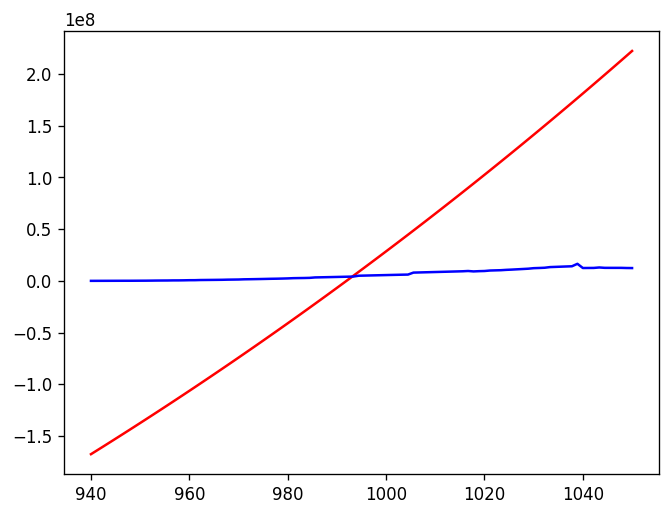

In [13]:
muB_test = np.linspace(940, 1050, 100)
y1 = PQM(muB_test, 0, B)
y2 = np.array([PNM_Walecka(x) for x in muB_test])

plt.plot(muB_test, y1, color='r')
plt.plot(muB_test, y2, color='b')

#### problems

* $P_{NM}(\mu_B)$ or $P_{NM}(k_F)$
* numerical solution isn't accurate
* how to include electrons in Walecka model?

# Prior to June 1

In [9]:
# coupling constants are determined by requiring that the model reproduces saturation density and binding energy per nucleon
alpha_sigma = 9.573
g_sigma = np.sqrt(alpha_sigma * 4 * np.pi)

alpha_omega = 14.717
g_omega = np.sqrt(alpha_omega * 4 * np.pi)

m_sigma = 550  # MeV
m_omega = 783  # MeV
m_N = m_B

#### relative residue

In [12]:
def system(vars):
    k_F, sigma_bar, omega_0_bar = vars
    if k_F <= 0 or sigma_bar < 0:
        return [1e6, 1e6, 1e6]

    m_star = m_N - g_sigma * sigma_bar
    if m_star <= 0:
        return [1e6, 1e6, 1e6]

    E_F = np.sqrt(k_F**2 + m_star**2)
    eq1 = E_F + g_omega * omega_0_bar - mu_B

    eq2 = omega_0_bar - (g_omega / m_omega**2) * (2 * k_F**3) / (3 * np.pi**2)

    log_arg = (k_F + E_F) / m_star
    if log_arg <= 0:
        return [1e6, 1e6, 1e6]
    scalar_term = k_F * E_F - m_star**2 * np.log(log_arg)
    eq3 = -sigma_bar + (g_sigma / m_sigma**2) * m_star * scalar_term / (np.pi**2)

    return [eq1, eq2, eq3]

# --- Initial guess ---
initial_guess = [200.0, 0.05, 5.0]

# --- Solve the system ---
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)
    sol = fsolve(system, initial_guess, xtol=1e-10)

# --- Unpack solution ---
k_F_sol, sigma_bar_sol, omega_0_bar_sol = sol

# --- Recompute individual components ---
m_star = m_N - g_sigma * sigma_bar_sol
E_F = np.sqrt(k_F_sol**2 + m_star**2)

# Eq1: E_F + g_omega * omega_0_bar = mu_B
lhs1 = E_F + g_omega * omega_0_bar_sol
rel_res1 = abs(lhs1 - mu_B) / abs(lhs1)

# Eq2: omega_0_bar = (g_omega / m_omega^2) * (2 k_F^3)/(3 pi^2)
rhs2 = (g_omega / m_omega**2) * (2 * k_F_sol**3) / (3 * np.pi**2)
rel_res2 = abs(omega_0_bar_sol - rhs2) / abs(rhs2)

# Eq3
log_arg = (k_F_sol + E_F) / m_star
scalar_term = k_F_sol * E_F - m_star**2 * np.log(log_arg)
rhs3 = (g_sigma / m_sigma**2) * m_star * scalar_term / (np.pi**2)
rel_res3 = abs(sigma_bar_sol - rhs3) / abs(rhs3)

# --- Output ---
print("✅ FSOLVE Solution:")
print(f"  k_F        = {k_F_sol:.4f} MeV")
print(f"  σ̄          = {sigma_bar_sol:.4f}")
print(f"  ω̄₀         = {omega_0_bar_sol:.4f}")
print()
print("📊 Relative Residuals:")
print(f"  Eq1: |LHS - RHS| / |LHS| = {rel_res1:.2e}")
print(f"  Eq2: |LHS - RHS| / |RHS| = {rel_res2:.2e}")
print(f"  Eq3: |LHS - RHS| / |RHS| = {rel_res3:.2e}")

✅ FSOLVE Solution:
  k_F        = 84.3040 MeV
  σ̄          = 0.0229
  ω̄₀         = 2.7486

📊 Relative Residuals:
  Eq1: |LHS - RHS| / |LHS| = 9.64e-05
  Eq2: |LHS - RHS| / |RHS| = 2.06e+00
  Eq3: |LHS - RHS| / |RHS| = 9.84e-01


#### Using $k_F$ rep

In [13]:
def PNM(k_F):
    muB = np.sqrt(k_F**2 + m_B**2)
    muE = (muB**2 - m_B**2) / (2 * muB) # solved using MMA, this corresponds to the real solution
    muQ = -muE
    mun = muB
    mup = muB + muQ
    return P_f(mun, m_B) + P_f(mup, m_B) + muE**4 / (12 * np.pi**2), muB

def PNM_old(muB):
    muE = (muB**2 - m_B**2) / (2 * muB) # solved using MMA, this corresponds to the real solution
    muQ = -muE
    mun = muB
    mup = muB + muQ
    return P_f(mun, m_B) + P_f(mup, m_B) + muE**4 / (12 * np.pi**2)

In [14]:
k_F = 90

# --- Eq3: function of sigma_bar ---
def eq3_sigma(sigma_bar):
    m_star = m_N - g_sigma * sigma_bar
    if m_star <= 0:
        return 1e6
    E_F = np.sqrt(k_F**2 + m_star**2)
    log_arg = (k_F + E_F) / m_star
    if log_arg <= 0:
        return 1e6
    scalar_term = k_F * E_F - m_star**2 * np.log(log_arg)
    rhs = (g_sigma / m_sigma**2) * m_star * scalar_term / (np.pi**2)
    return -sigma_bar + rhs

# --- Solve Eq3 ---
initial_guess = 0.02
sigma_bar_sol = fsolve(eq3_sigma, initial_guess, xtol=1e-10)[0]

# --- Calculate m_star and E_F again ---
m_star_sol = m_N - g_sigma * sigma_bar_sol
E_F = np.sqrt(k_F**2 + m_star_sol**2)

# --- Eq2: omega_0_bar ---
omega_0_bar_sol = (g_omega / m_omega**2) * (2 * k_F**3) / (3 * np.pi**2)

# --- Eq1: mu_B ---
mu_B_sol = E_F + g_omega * omega_0_bar_sol

# --- Residual checks ---

# Eq1: E_F + g_omega * omega_0_bar = mu_B
lhs1 = E_F + g_omega * omega_0_bar_sol
rel_res1 = abs(lhs1 - mu_B_sol) / abs(lhs1)

# Eq2: omega_0_bar = ...
rhs2 = (g_omega / m_omega**2) * (2 * k_F**3) / (3 * np.pi**2)
rel_res2 = abs(omega_0_bar_sol - rhs2) / abs(rhs2)

# Eq3: the original residual
log_arg = (k_F + E_F) / m_star_sol
scalar_term = k_F * E_F - m_star_sol**2 * np.log(log_arg)
rhs3 = (g_sigma / m_sigma**2) * m_star_sol * scalar_term / (np.pi**2)
rel_res3 = abs(sigma_bar_sol - rhs3) / abs(rhs3)

# --- Output ---
print("✅ Solved values given known k_F:")
print(f"  k_F        = {k_F:.4f} MeV")
print(f"  σ̄          = {sigma_bar_sol:.6f}")
print(f"  ω̄₀         = {omega_0_bar_sol:.6f}")
print(f"  μ_B         = {mu_B_sol:.6f} MeV\n")

print("📊 Relative Residuals:")
print(f"  Eq1: |LHS - RHS| / |LHS| = {rel_res1:.2e}")
print(f"  Eq2: |LHS - RHS| / |RHS| = {rel_res2:.2e}")
print(f"  Eq3: |LHS - RHS| / |RHS| = {rel_res3:.2e}")

✅ Solved values given known k_F:
  k_F        = 90.0000 MeV
  σ̄          = 1.780313
  ω̄₀         = 1.092264
  μ_B         = 938.721608 MeV

📊 Relative Residuals:
  Eq1: |LHS - RHS| / |LHS| = 0.00e+00
  Eq2: |LHS - RHS| / |RHS| = 0.00e+00
  Eq3: |LHS - RHS| / |RHS| = 2.96e-14


#### Defining the function that calculate pressure

In [15]:
# --- Function to compute P and mu_B given k_F ---
def PNM_Walecka(k_F):
    # Equation to solve: Eq3 for sigma_bar
    def eq3_sigma(sigma_bar):
        m_star = m_N - g_sigma * sigma_bar
        if m_star <= 0:
            return 1e6
        E_F = np.sqrt(k_F**2 + m_star**2)
        log_arg = (k_F + E_F) / m_star
        if log_arg <= 0:
            return 1e6
        scalar_term = k_F * E_F - m_star**2 * np.log(log_arg)
        rhs = (g_sigma / m_sigma**2) * m_star * scalar_term / (np.pi**2)
        return -sigma_bar + rhs

    # Solve for sigma_bar
    sigma_bar = fsolve(eq3_sigma, 0.02, xtol=1e-10)[0]
    m_star = m_N - g_sigma * sigma_bar

    # Compute omega_0_bar
    omega_0_bar = (g_omega / m_omega**2) * (2 * k_F**3) / (3 * np.pi**2)

    # Compute effective Fermi energy
    E_F_star = np.sqrt(k_F**2 + m_star**2)

    # Compute true baryon chemical potential
    mu_B = E_F_star + g_omega * omega_0_bar

    # Compute pressure
    term1 = 0.5 * m_omega**2 * omega_0_bar**2
    term2 = 0.5 * m_sigma**2 * sigma_bar**2
    term3 = ((2/3) * k_F**3 - m_star**2 * k_F) * E_F_star
    term4 = m_star**4 * np.log((k_F + E_F_star) / m_star)
    kinetic_term = (term3 + term4) / (4 * np.pi**2)

    pressure = term1 - term2 + kinetic_term

    return pressure, mu_B

In [16]:
k_F = 90  # example in MeV
P, muB = PNM_Walecka(k_F)

print(f"Results for k_F = {k_F:.3f} MeV")
print(f"  Pressure P   = {P:.4f} MeV⁴")
print(f"  μ_B          = {muB:.4f} MeV")

Results for k_F = 90.000 MeV
  Pressure P   = -27205.8436 MeV⁴
  μ_B          = 938.7216 MeV


#### Compare with PQM bag model, truncate $k_F$'s making $P_{NM}<0$

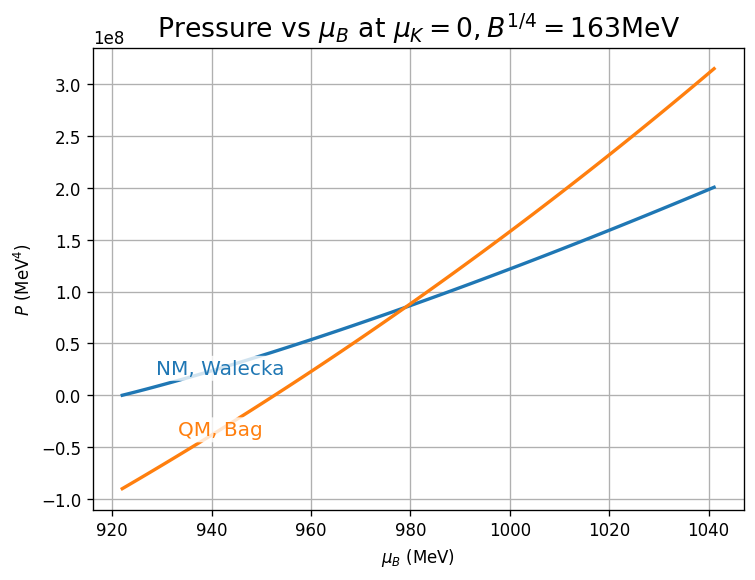

In [17]:
kF = np.linspace(260, 310, 100)  # 43

'''
P_nonint = []
muB_nonint = [] 
for k_F in kF:
    tmp1, tmp2 = PNM(k_F)
    P_nonint.append(tmp1)
    muB_nonint.append(tmp2)
'''

P_W = []
muB_W = []
for k_F in kF:
    tmp1, tmp2 = PNM_Walecka(k_F)
    P_W.append(tmp1)
    muB_W.append(tmp2)
P_QM = PQM(np.array(muB_W), 0, B)

B_one_forth = 163
B = B_one_forth**4

plt.figure(figsize=(7, 5))

#plt.plot(muB_W, [PNM_old(x) for x in muB_W], 'b')
plt.plot(muB_W, P_W, lw=2, color='tab:blue')
#plt.plot(np.linspace(910, 1010, 100), np.zeros(100), 'k')
plt.plot(muB_W, P_QM, lw=2, color='tab:orange')
plt.xlabel(r'$\mu_B$ (MeV)')
plt.ylabel(r'$P$ (MeV$^4$)')
#plt.text(980, 5e+6, "Non-interacting")
#plt.text(965, 8e+7, "Walecka")

boxprops = dict(boxstyle='round,pad=0.15', facecolor='white', edgecolor='none', alpha=0.8)

plt.text(muB_W[33], P_W[33], "NM, Walecka", fontsize=12, color='tab:blue', ha='center', va='center', bbox=boxprops)
plt.text(muB_W[33],  PQM(muB_W[33], 0, B),  "QM, Bag", fontsize=12, color='tab:orange', ha='center', va='center', bbox=boxprops)

plt.title(r'Pressure vs $\mu_B$ at $\mu_K = 0, B^{1/4}=$'+str(B_one_forth)+'MeV', fontsize=16)
plt.grid(True)

# Prior to Jun 2

978.9957951851839


Text(980, 3, 'Critical, $\\mu_B = $MeV')

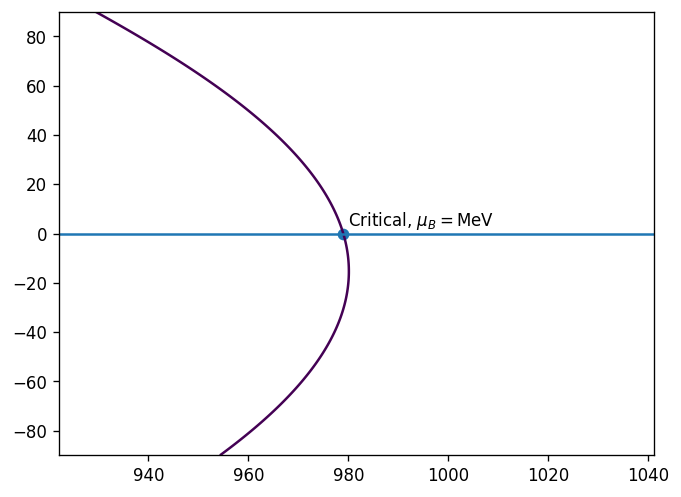

In [20]:
B_one_forth = 163
B = B_one_forth**4
muK = np.linspace(-90,90,500)
kF = np.linspace(260, 310, 1000)

muB = []
P_NM = np.ones([len(kF), len(muK)])
for i in range(len(kF)):
    tmp1, tmp2 = PNM_Walecka(kF[i])
    muB.append(tmp2)
    for j in range(len(muK)):
        P_NM[i,j] = tmp1

muK_grid, muB_grid = np.meshgrid(muK, muB)
P_QM = PQM(muB_grid, muK_grid, B)

contours = plt.contour(muB_grid, muK_grid, P_QM - P_NM, levels=[0])
#contours = plt.contour(muB_grid, muK_grid, P_QM, levels=[0])
plt.plot(muB, np.zeros(len(muB)))

muB_contour_coor, muK_contour_coor = extract_contour_coords(muB_grid, muK_grid, P_QM - P_NM, level = 0)
min_ind = np.argmin(np.abs(muK_contour_coor))
muB_crit = muB_contour_coor[min_ind]
print(muB_crit)
P_crit = PQM(muB_crit, 0, B)

#PNM_minus_PShift = lambda x: PNM_Walecka(x)[0] - P_crit #- Delta_P
#muB_crit = PNM_Walecka(fsolve(PNM_minus_PShift, 1050))[1]

plt.scatter(muB_crit,0) # 978.8
plt.text(980, 3, r"Critical, $\mu_B = $MeV")

#muB_crit
#muB_crit = 978.8
#P_crit = PQM(muB_crit, 0, B)

/var/folders/zx/mchmm24s5sj4l19_jxvlkj380000gn/T/ipykernel_23249/3901125635.py:11: RuntimeWarning: invalid value encountered in sqrt
  k_F = np.sqrt(mu**2 - m**2)


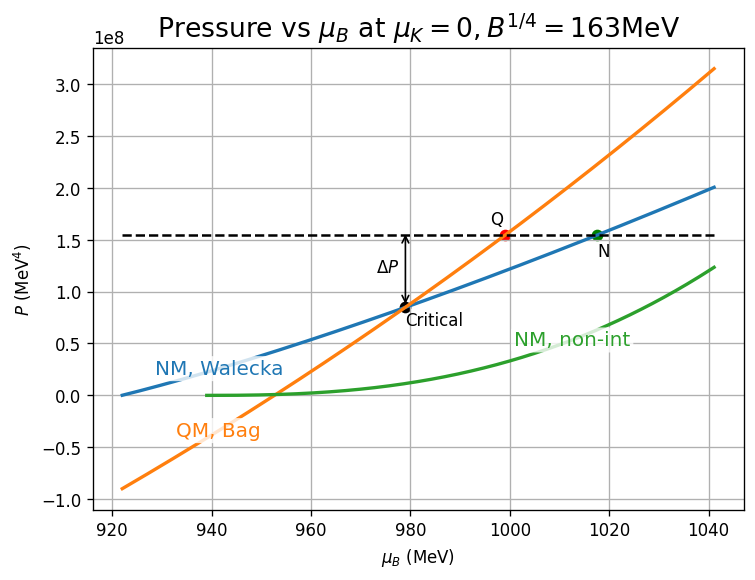

In [21]:
muK = np.linspace(-90,90,500)
kF = np.linspace(260, 310, 1000)

P_W = []
muB_W = []
for k_F in kF:
    tmp1, tmp2 = PNM_Walecka(k_F)
    P_W.append(tmp1)
    muB_W.append(tmp2)
P_QM_equ = PQM(np.array(muB_W), 0, B)

P_W = np.array(P_W)
muB_W = np.array(muB_W)

Delta_P = 7e+7

plt.figure(figsize=(7, 5))

#plt.plot(muB_W, [PNM_old(x) for x in muB_W], 'b')
plt.plot(muB_W, P_W, lw=2, color='tab:blue')
#plt.plot(np.linspace(910, 1010, 100), np.zeros(100), 'k')
plt.plot(muB_W, P_QM_equ, lw=2, color='tab:orange')
plt.plot(muB_W, PNM_old(muB_W), lw=2, color='tab:green')
plt.xlabel(r'$\mu_B$ (MeV)')
plt.ylabel(r'$P$ (MeV$^4$)')
#plt.text(980, 5e+6, "Non-interacting")
#plt.text(965, 8e+7, "Walecka")

boxprops = dict(boxstyle='round,pad=0.15', facecolor='white', edgecolor='none', alpha=0.8)

plt.text(muB_W[330], P_W[330], "NM, Walecka", fontsize=12, color='tab:blue', ha='center', va='center', bbox=boxprops)
plt.text(muB_W[330],  P_QM_equ[330],  "QM, Bag", fontsize=12, color='tab:orange', ha='center', va='center', bbox=boxprops)
plt.text(muB_W[860],  PNM_old(muB_W[860]),  "NM, non-int", fontsize=12, color='tab:green', ha='center', va='center', bbox=boxprops)

plt.scatter(muB_crit, P_crit, c='k') # 3.6e+7
plt.text(muB_crit, 0.8*P_crit, r"Critical")
plt.plot(muB, (P_crit + Delta_P)*np.ones(len(muB)), 'k--')
plt.scatter(999, PQM(999, 0, B), c='r')
plt.text(996, PQM(996,0,B)*1.15, r"Q")
P_tmp, muB_tmp = PNM_Walecka(304.35)
plt.scatter(muB_tmp, P_tmp, c='g')
plt.text(muB_tmp, 0.87*P_tmp, r"N")

plt.annotate(
    '', 
    xy=(muB_crit, P_crit), 
    xytext=(muB_crit, P_crit+Delta_P*1.05
           ),
    arrowprops=dict(arrowstyle='<->', color='black', lw=1.0),
)
# Optional label for the arrow
plt.text(muB_crit-6, (P_crit + Delta_P)/1.25, r'$\Delta P$', va='center')


plt.title(r'Pressure vs $\mu_B$ at $\mu_K = 0, B^{1/4}=$'+str(B_one_forth)+'MeV', fontsize=16)
plt.grid(True)

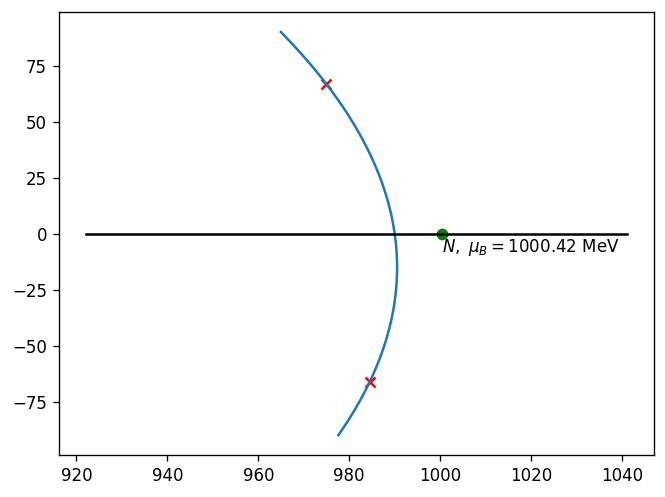

In [341]:
Delta_P = 4e+7

B_one_forth = 163
B = B_one_forth**4
muK = np.linspace(-90,90,100)
kF = np.linspace(260, 310, 200)

muB = []
P_NM = np.ones([len(kF), len(muK)])
for i in range(len(kF)):
    tmp1, tmp2 = PNM_Walecka(kF[i])
    muB.append(tmp2)
    for j in range(len(muK)):
        P_NM[i,j] = tmp1

muK_grid, muB_grid = np.meshgrid(muK, muB)
P_QM = PQM(muB_grid, muK_grid, B)

# need to extract the contour curve for later use, such as calculating baryon density and kaon density at each point on the contour
def extract_contour_coords(X, Y, Z, level):
    fig, ax = plt.subplots()
    contour_obj = ax.contour(X, Y, Z, levels=[level])
    # Directly access the paths from the contour object
    paths = []
    for c in contour_obj.get_paths():
        paths.append(c.vertices)
    plt.close(fig)  # Close the plot if you only want data
    if not paths:
        raise RuntimeError(f"No contours found at level {level}")
    return paths[0][:, 0], paths[0][:, 1]

# plot contour
muB_contour_coor, muK_contour_coor = extract_contour_coords(muB_grid, muK_grid, P_QM, level = P_crit + Delta_P)
plt.plot(muB_contour_coor, muK_contour_coor)
plt.plot(muB, np.zeros(len(muB)), 'k')

# plotting N
PNM_minus_PShift = lambda x: PNM_Walecka(x)[0] - P_crit - Delta_P
muB_N = PNM_Walecka(fsolve(PNM_minus_PShift, 1050))[1]
plt.scatter(muB_N,0, c='g')
plt.text(muB_N, -8, rf"$N,\ \mu_B = {muB_N.item():.2f}\ \mathrm{{MeV}}$")

# plotting cross
mu_average = []
for i in range(len(muB_contour_coor)):
    muB_Qstar = muB_contour_coor[i]
    muK_Qstar = muK_contour_coor[i]
    Qstar = np.array([muB_Qstar, muK_Qstar])
    grad = approx_fprime(Qstar, PQM_wrap, epsilon) # calculate n=∂P/∂mu
    nB_Qstar = grad[0]
    nK_Qstar = grad[1]
    mu_average.append( muB_Qstar + nK_Qstar * muK_Qstar / nB_Qstar)
difference = np.abs(np.array(mu_average) - muB_N)
minima_ind = argrelextrema(difference, np.less)[0]

plt.scatter(muB_contour_coor[minima_ind[0]],muK_contour_coor[minima_ind[0]], marker='x', c='r')
plt.scatter(muB_contour_coor[minima_ind[1]],muK_contour_coor[minima_ind[1]], marker='x', c='r')

#plt.scatter(np.array([i for i in range(len(mu_average))]), mu_average, s=0.1)
#plt.plot(np.array([i for i in range(len(mu_average))]), muB_N*np.ones(len(mu_average)))

In [22]:
minima_ind

array([ 1, 74])

#### Solve for $\mu_B^N$ from $P_{NM} = P_{crit} + \Delta P$

In [23]:
PNM_minus_PShift = lambda x: PNM_Walecka(x)[0] - P_crit - Delta_P
muB_N = PNM_Walecka(fsolve(PNM_minus_PShift, 1050))[1]
muB_N

array([1017.7744061])

In [24]:
from scipy.optimize import approx_fprime

def aQstar_and_other_stuff(muB, muK, P_crit, Delta_P):  # the muB should be understood as muB_Qstar, and same for muK
    # calculate nB_Qstar, nK_Qstar using partial derivitives
    Qstar = np.array([muB, muK])
    grad_Qstar = approx_fprime(Qstar, PQM_wrap, epsilon) # calculate n=∂P/∂mu at Qstar!!!
    nB_Qstar = grad_Qstar[0]
    nK_Qstar = grad_Qstar[1]

    # solve for muB_Q
    PQM_at_Q = lambda x: PQM(x, 0, B) - P_crit - Delta_P
    muB_Q = fsolve(PQM_at_Q, 1050)[0]  # 1050 is the starting point of numerical root finding

    # calculate nB_Q and nK_Q using partial derivitives
    Q = np.array([muB_Q, 0])  # the point Q
    grad_Q = approx_fprime(Q, PQM_wrap, epsilon)
    nB_Q = grad_Q[0]
    nK_Q = grad_Q[1]

    return (nK_Qstar - nK_Q)/nB_Q , nB_Q, muB_Q

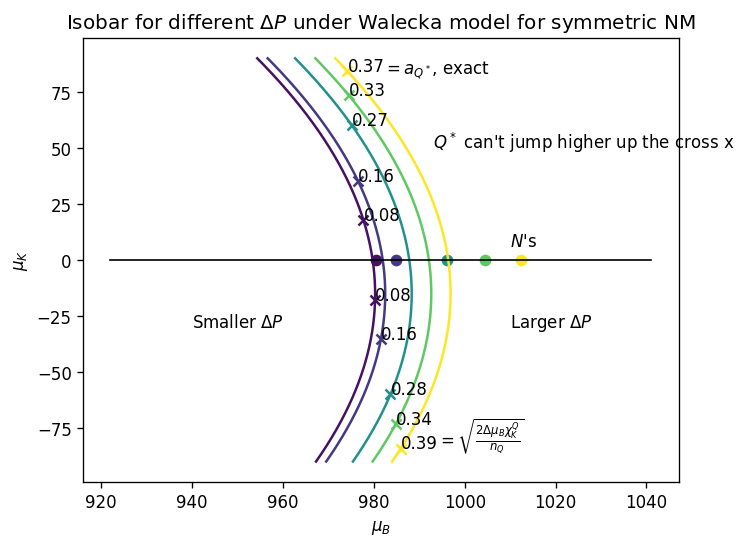

In [25]:
from scipy.signal import argrelextrema
from scipy.optimize import fsolve
import numdifftools as nd
from matplotlib import colormaps
cmap = colormaps['viridis']

Delta = np.array([2.5e+6, 1e+7, 3e+7, 4.5e+7, 6e+7]) #P_crit * np.array([0.1, 0.2, 0.3, 0.4, 0.5])

for Delta_P in Delta:
    muB_contour_coor, muK_contour_coor = extract_contour_coords(muB_grid, muK_grid, P_QM, level = P_crit + Delta_P)
    mu_average = []
    for i in range(len(muB_contour_coor)):
        muB_Qstar = muB_contour_coor[i]
        muK_Qstar = muK_contour_coor[i]
        Qstar = np.array([muB_Qstar, muK_Qstar])
        grad = approx_fprime(Qstar, PQM_wrap, epsilon) # calculate n=∂P/∂mu at Qstar!!!
        nB_Qstar = grad[0]
        nK_Qstar = grad[1]
        mu_average.append( muB_Qstar + nK_Qstar * muK_Qstar / nB_Qstar)
    PNM_minus_PShift = lambda x: PNM_Walecka(x)[0] - P_crit - Delta_P
    muB_N = PNM_Walecka(fsolve(PNM_minus_PShift, 1050))[1]
    difference = np.abs(np.array(mu_average) - muB_N)
    minima_ind = argrelextrema(difference, np.less)[0]  # this is where the cross is (the index) along the contour line

    muB_Qstar_down = muB_contour_coor[minima_ind[0]]
    muK_Qstar_down = muK_contour_coor[minima_ind[0]]
    muB_Qstar_up = muB_contour_coor[minima_ind[1]]
    muK_Qstar_up = muK_contour_coor[minima_ind[1]]
    
    a_Q_star, nBQ, muBQ = aQstar_and_other_stuff(muB_Qstar_up, muK_Qstar_up, P_crit, Delta_P) # should only use upper value

    # the following calculates a_Q_star_max using the analytical approximation from taylor expansion
    PQM_at_Q = lambda x: PQM(muBQ, x, B) - P_crit - Delta_P
    d2f = nd.Derivative(PQM_at_Q, n=2)
    chiK_Q = d2f(0)
    a_Q_star_max = np.sqrt((2 * (muB_N - muBQ) * chiK_Q) / nBQ)[0]

    # plotting the crosses and the corresponding exact aQstar (on upper branch) and analytical aQstar (on down branch)
    col = cmap(Delta_P/Delta[-1])
    plt.plot(muB_contour_coor, muK_contour_coor, color = col)
    plt.scatter(muB_Qstar_down,muK_Qstar_down, marker='x', color=col)
    plt.scatter(muB_Qstar_up,muK_Qstar_up, marker='x', color=col)
    plt.text(muB_Qstar_up,muK_Qstar_up, f"{a_Q_star:.2f}")
    plt.text(muB_Qstar_down,muK_Qstar_down, f"{a_Q_star_max:.2f}")
    plt.scatter(muB_N, 0, color=col)
    

plt.text(1010, -30, r"Larger $\Delta P$")
plt.text(940, -30, r"Smaller $\Delta P$")
plt.text(993, 50, r"$Q^*$ can't jump higher up the cross x")
plt.text(982, 83, r"$=a_{Q^*}$, exact")
plt.text(994, -83, r"$=\sqrt{\frac{2\Delta\mu_B\chi_K^Q}{n_Q}}$")
plt.text(1010, 6, r"$N$'s")
plt.plot(muB, np.zeros(len(muB)), 'k', lw=1)
plt.xlabel(r"$\mu_B$")
plt.ylabel(r"$\mu_K$")
plt.title(r"Isobar for different $\Delta P$ under Walecka model for symmetric NM") 
plt.show()

we see it's similar to what we got from non-interacting NM model, but details are different, which comes from the fact that Walecka model has smaller $\chi_B$, i.e. the $P(\mu_B)$ curve is less convex

# $QMC-RMFx$ models for NM

#### Questions

$$
\boldsymbol{\rho}_\nu\cdot
\left[
\frac{1}{2} \overline{\psi} \gamma^\nu \boldsymbol{\tau} \psi 
+ \boldsymbol{\rho}_\mu \times \boldsymbol{\rho}^{\nu\mu} 
+ 2 g_\rho (\boldsymbol{\rho}^\nu \times \boldsymbol{\rho}^\mu) \times \boldsymbol{\rho}_\mu
\right]
$$

* isospin force term above; my understanding: the mass of $\rho$ messon indicates it should enter the theory.
> not correct, they're having same quantum number, but they're not actual particles; they're various VEV's that helps us out the mess of low energy QCD
* is it from some gauge symmetry, or just comes from EFT?
> can think this way, but there's no such gauge symmetry behind; RMFs is a phenomenological model
* an approach not using path integral
> just different methods

* so now, are we exploring more and more realistic models? this gives me chances to learn for sure, but I also wanna to be creative
> find acceptible models for neutron rish NM, and use it to illustrate our  point. try to be creative for phase boundary; can use our own model for NM, the $QMC-RMFn$ models
* do we have better models for SQM? there's a paper a few days ago uses NJL type QM model: [2505.21970v1], the author had a similar one a year ago: [2407.13990v1]
> this is a direction beyond the first paper
* My understanding is that there are other SQM models, but now we still can't tell are they good enough
> same question as the above one. to define good or not: does it help us to make our point socialogically; can consider NJL model, but bag model should be good for this cruid first paper in this field
* I've also been thinking about is there physics that can tell us exactly where does $Q^*$ lands. Am I in a better position to think about this?
> this is a better question than picking models, but maybe having an upper bound on $a_{Q^*}$, indicating an upper bound on velocity, is good enough to make the point. 
* SQM hypothesis gives us another constraint $a<0.5$ from Olinto's paper which comes from Farhi and Jaffe's original idea.
> our case is a weaker statement: SQM is prefered at higher temperature instead of at zero temperature, so this constraint from Farhi and Jaffe doesn't give us anything new

**things next: pure neutron matter using RMF model with rho mesons.**

# Prior to 16 June

A small question: the merger doesn't have spherical symmetry, so why can we still assume the $i,j,k$ components of Lorentz index for rho meson mean field vanish?